# Stochastic Taxi Driver: Q-Learning Algorithm

## Setup

In [1]:
import random
from IPython.display import clear_output
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import numpy as np

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

from algorithms.QLearning import QLearning

from numpy import loadtxt
from IPython.display import clear_output
from time import sleep

In [2]:
# environment
env = gym.make("Taxi-v4", is_rainy=True, rainy_probability=0.6, render_mode='ansi')

## Train

In [3]:
alpha = 0.5
gamma=0.7
epsilon=0.2
epsilon_min=0.05
epsilon_dec=0.99
episodes=10000

In [4]:
all_rewards = []
q_tables = []

for execution in range(5):
    
    qlearn = QLearning(env, alpha=alpha, gamma=gamma, epsilon=epsilon, epsilon_min=epsilon_min, epsilon_dec=epsilon_dec, episodes=episodes)
    q_table, rewards = qlearn.train("../../data/stochastic/q-table-stochastic-taxidriver.csv")

    q_tables.append(q_table)
    all_rewards.append(rewards)

    env.close()

## Plot

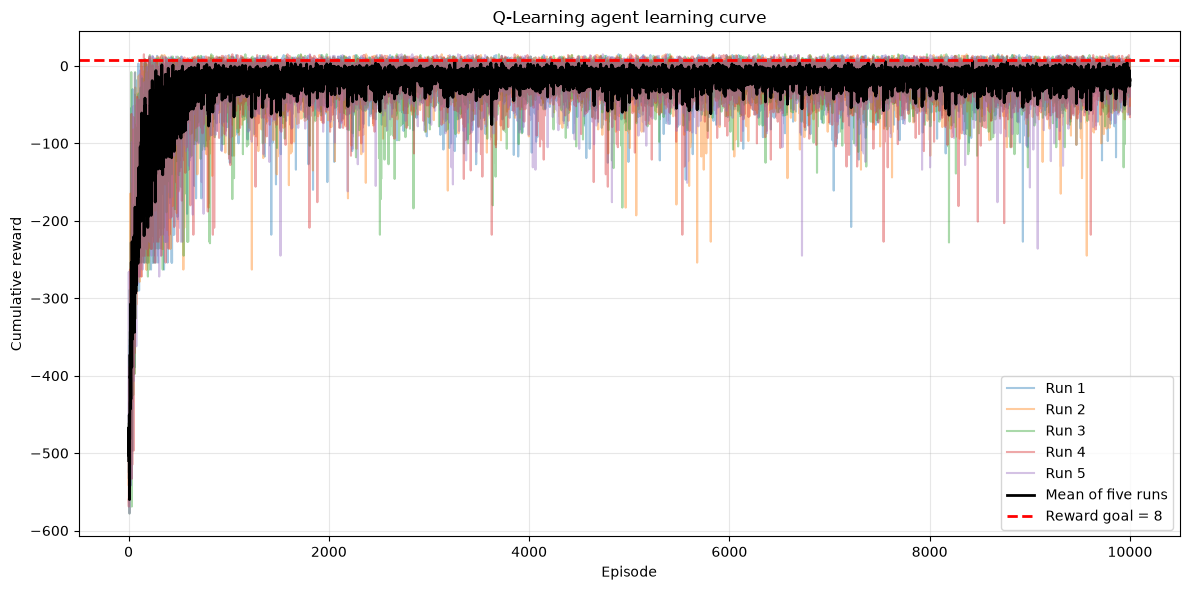

In [5]:
reward_goal = 8
episodes_axis = np.arange(1, episodes + 1)

plt.figure(figsize=(12, 6))

for execution, rewards in enumerate(all_rewards, start=1):
    plt.plot(
        episodes_axis,
        rewards,
        alpha=0.4,
        label=f"Run {execution}"
    )

mean_rewards = np.mean(all_rewards, axis=0)

plt.plot(episodes_axis, mean_rewards, color="black", linewidth=2, label="Mean of five runs")
plt.axhline(y=reward_goal, color="red", linestyle="--", linewidth=2, label=f"Reward goal = {reward_goal}")

plt.xlabel("Episode")
plt.ylabel("Cumulative reward")
plt.title("Q-Learning agent learning curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Test

In [6]:
q_table = loadtxt('../../data/stochastic/q-table-stochastic-taxidriver.csv', delimiter=',')
env = gym.make("Taxi-v4", is_rainy=True, rainy_probability=0.6)
render_env = gym.make("Taxi-v4", is_rainy=True, rainy_probability=0.6, render_mode='human')

n_runs = 100
timesteps_per_run = []
successes = 0

for run in range(n_runs):
    # render only the last run
    run_env = render_env if run == n_runs - 1 else env

    (state, _) = run_env.reset(seed=run)
    done = False
    truncated = False
    timesteps = 0

    while not (done or truncated):
        action = np.argmax(q_table[state])
        state, reward, done, truncated, info = run_env.step(action)
        timesteps += 1

    timesteps_per_run.append(timesteps)
    if done:
        successes += 1

env.close()
render_env.close()

mean_timesteps = np.mean(timesteps_per_run)
std_timesteps = np.std(timesteps_per_run, ddof=1)

print(f"Successful runs: {successes}/{n_runs}")
print(f"Timesteps: mean = {mean_timesteps:.2f}, std = {std_timesteps:.2f}")

Successful runs: 99/100
Timesteps: mean = 33.28, std = 26.10


In [7]:
rewards_dir = Path("../../data/rewards")
rewards_dir.mkdir(parents=True, exist_ok=True)
np.savetxt(rewards_dir / "qlearning_stochastic.csv", np.array(all_rewards), delimiter=",", fmt="%d")